# 02 — Ensemble MedGemma + MedSigLIP
**Dataset:** CheXpert v1

MedGemma dan MedSigLIP memiliki profil komplementer:
- MedGemma: precision tinggi, sensitivity rendah (konservatif)
- MedSigLIP: AUROC lebih baik, distribusi confidence lebih smooth

Strategi ensemble yang diuji:
1. **Score average** (50/50, gem-heavy 70/30, sip-heavy 30/70)
2. **Max score** — ambil skor tertinggi dari kedua model
3. **AND voting** — PTX hanya jika keduanya setuju → precision tinggi
4. **OR voting** — PTX jika salah satu deteksi → sensitivity tinggi

Semua score-based ensemble menggunakan MedGemma reinterpreted score (P(PTX) yang sudah direction-aware).

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

PROJECT_ROOT = Path(os.getcwd()).parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src2.utils import load_results
from src2_1.ensemble import (
    reinterpret_gemma_score, get_medsiglip_ptx_score,
    align_on_file_id, metrics_from_score, metrics_from_pred,
    vote_and, vote_or,
)

DATASET    = 'chexpert_v1'
RESULTS_IN = PROJECT_ROOT / 'hasil_penelitian_2' / 'outputs' / DATASET
OUT_DIR    = PROJECT_ROOT / 'hasil_penelitian_2_1' / 'outputs' / DATASET
FIG_DIR    = OUT_DIR / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
print(f'Dataset: {DATASET}')

Dataset: chexpert_v1


In [2]:
# ── Load & align ──────────────────────────────────────────────────────────────
df_gem_raw = pd.DataFrame(load_results(RESULTS_IN / 'medgemma.jsonl'))
df_sip_raw = pd.DataFrame(load_results(RESULTS_IN / 'medsiglip.jsonl'))

df_gem, df_sip = align_on_file_id(df_gem_raw, df_sip_raw)
print(f'Aligned: {len(df_gem)} samples (gemeinsam)')

y_true    = df_gem['label_gt'].values
score_gem = reinterpret_gemma_score(df_gem)   # direction-aware P(PTX)
score_sip = get_medsiglip_ptx_score(df_sip)   # cosine similarity P(PTX)
pred_gem  = df_gem['diagnosis'].values.astype(int)
pred_sip  = df_sip['diagnosis'].values.astype(int)

print(f'Score MedGemma (reinterp.): [{score_gem.min():.3f}, {score_gem.max():.3f}]')
print(f'Score MedSigLIP (cosine)  : [{score_sip.min():.3f}, {score_sip.max():.3f}]')
print(f'\nLabel distribution: PTX={y_true.sum()}, Normal={(y_true==0).sum()}')

Aligned: 1050 samples (gemeinsam)
Score MedGemma (reinterp.): [0.100, 0.900]
Score MedSigLIP (cosine)  : [0.031, 0.928]

Label distribution: PTX=500, Normal=550


In [3]:
# ── Evaluate semua strategi ───────────────────────────────────────────────────
strategies = {}

# Baseline: individual models
score_raw_gem = df_gem['confidence_explicit'].values.astype(float) / 10.0
strategies['MedGemma (original)']    = metrics_from_score(y_true, score_raw_gem)
strategies['MedGemma (reinterp.)']   = metrics_from_score(y_true, score_gem)
strategies['MedSigLIP']              = metrics_from_score(y_true, score_sip)

# Score-based ensemble
for w_gem, label in [
    (0.5, 'Ensemble avg (50/50)'),
    (0.7, 'Ensemble gem-heavy (70/30)'),
    (0.3, 'Ensemble sip-heavy (30/70)'),
]:
    ens = w_gem * score_gem + (1 - w_gem) * score_sip
    strategies[label] = metrics_from_score(y_true, ens)

strategies['Ensemble max-score'] = metrics_from_score(
    y_true, np.maximum(score_gem, score_sip)
)

# Vote-based ensemble
strategies['Ensemble AND (high prec.)'] = metrics_from_pred(y_true, vote_and(pred_gem, pred_sip))
strategies['Ensemble OR (high sens.)']  = metrics_from_pred(y_true, vote_or(pred_gem, pred_sip))

# Summary table
print(f'\n{"Strategy":<35} {"F1":>6} {"Sens":>6} {"Spec":>6} {"Prec":>6} {"AUROC":>7}')
print('─' * 68)
for name, m in strategies.items():
    auroc_str = f"{m['auroc']:.4f}" if m['auroc'] is not None else '  N/A '
    print(f'{name:<35} {m["f1"]:>6.4f} {m["sensitivity"]:>6.4f} {m["specificity"]:>6.4f} {m["precision"]:>6.4f} {auroc_str:>7}')


Strategy                                F1   Sens   Spec   Prec   AUROC
────────────────────────────────────────────────────────────────────
MedGemma (original)                 0.6452 1.0000 0.0000 0.4762  0.4389
MedGemma (reinterp.)                0.6491 0.5680 0.8345 0.7573  0.7095
MedSigLIP                           0.4737 0.4780 0.5091 0.4695  0.4921
Ensemble avg (50/50)                0.6398 0.5560 0.8345 0.7534  0.6733
Ensemble gem-heavy (70/30)          0.6491 0.5680 0.8345 0.7573  0.6771
Ensemble sip-heavy (30/70)          0.5690 0.5280 0.7018 0.6168  0.6346
Ensemble max-score                  0.6230 0.7220 0.4582 0.5478  0.6711
Ensemble AND (high prec.)           0.4469 0.3240 0.8855 0.7200    N/A 
Ensemble OR (high sens.)            0.6230 0.7220 0.4582 0.5478    N/A 


In [4]:
# ── Best strategy per metric ──────────────────────────────────────────────────
df_res = pd.DataFrame(strategies).T

best_f1   = df_res['f1'].astype(float).idxmax()
best_sens = df_res['sensitivity'].astype(float).idxmax()
best_spec = df_res['specificity'].astype(float).idxmax()

print(f'Best F1           : {best_f1:<35} ({df_res.loc[best_f1, "f1"]:.4f})')
print(f'Best Sensitivity  : {best_sens:<35} ({df_res.loc[best_sens, "sensitivity"]:.4f})')
print(f'Best Specificity  : {best_spec:<35} ({df_res.loc[best_spec, "specificity"]:.4f})')

# Clinical threshold check (sensitivity >= 0.8)
print(f'\nStrategi yang mencapai sensitivity >= 0.80 (clinical threshold):')
for name, m in strategies.items():
    if m['sensitivity'] >= 0.80:
        print(f'  ✓ {name}: Sens={m["sensitivity"]:.4f}, Spec={m["specificity"]:.4f}, F1={m["f1"]:.4f}')

Best F1           : MedGemma (reinterp.)                (0.6491)
Best Sensitivity  : MedGemma (original)                 (1.0000)
Best Specificity  : Ensemble AND (high prec.)           (0.8855)

Strategi yang mencapai sensitivity >= 0.80 (clinical threshold):
  ✓ MedGemma (original): Sens=1.0000, Spec=0.0000, F1=0.6452


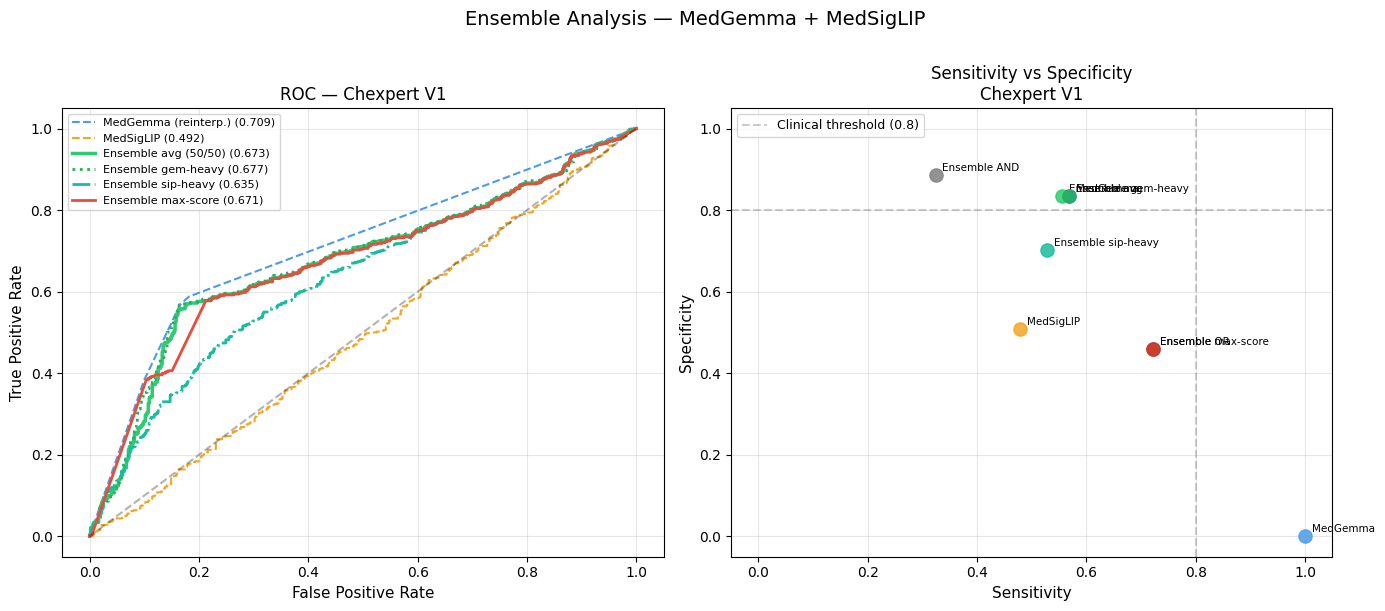

Saved: /data/arta/thoraxai_research/2_srg/hasil_penelitian_2_1/outputs/chexpert_v1/figures/ensemble_comparison.png


In [5]:
# ── ROC curves (score-based strategies) ──────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ROC curves
roc_configs = [
    ('MedGemma (reinterp.)',  score_gem,                           '#4C9BE8', '--', 1.5),
    ('MedSigLIP',             score_sip,                           '#F5A623', '--', 1.5),
    ('Ensemble avg (50/50)',  0.5*score_gem + 0.5*score_sip,       '#2ECC71', '-',  2.5),
    ('Ensemble gem-heavy',    0.7*score_gem + 0.3*score_sip,       '#27AE60', ':',  2.0),
    ('Ensemble sip-heavy',    0.3*score_gem + 0.7*score_sip,       '#1ABC9C', '-.',  2.0),
    ('Ensemble max-score',    np.maximum(score_gem, score_sip),    '#E74C3C', '-',  2.0),
]
for label, score, color, ls, lw in roc_configs:
    fpr, tpr, _ = roc_curve(y_true, score)
    auc = roc_auc_score(y_true, score)
    ax1.plot(fpr, tpr, color=color, linestyle=ls, linewidth=lw,
             label=f'{label} ({auc:.3f})')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate', fontsize=11)
ax1.set_title(f'ROC — {DATASET.replace("_", " ").title()}', fontsize=12)
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

# Sensitivity-Specificity scatter
colors_map = {
    'MedGemma (original)':       '#4C9BE8',
    'MedGemma (reinterp.)':      '#2980B9',
    'MedSigLIP':                 '#F5A623',
    'Ensemble avg (50/50)':      '#2ECC71',
    'Ensemble gem-heavy (70/30)':'#27AE60',
    'Ensemble sip-heavy (30/70)':'#1ABC9C',
    'Ensemble max-score':        '#E74C3C',
    'Ensemble AND (high prec.):':'#8E44AD',
    'Ensemble OR (high sens.)':  '#C0392B',
}
for name, m in strategies.items():
    color = colors_map.get(name, 'gray')
    ax2.scatter(m['sensitivity'], m['specificity'], s=90, color=color, alpha=0.85, zorder=5)
    ax2.annotate(name.split('(')[0].strip(), (m['sensitivity'], m['specificity']),
                 textcoords='offset points', xytext=(5, 3), fontsize=7.5)
ax2.axhline(0.8, color='gray', linestyle='--', alpha=0.4, label='Clinical threshold (0.8)')
ax2.axvline(0.8, color='gray', linestyle='--', alpha=0.4)
ax2.set_xlabel('Sensitivity', fontsize=11)
ax2.set_ylabel('Specificity', fontsize=11)
ax2.set_title(f'Sensitivity vs Specificity\n{DATASET.replace("_", " ").title()}', fontsize=12)
ax2.set_xlim(-0.05, 1.05)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=9)

plt.suptitle('Ensemble Analysis — MedGemma + MedSigLIP', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ensemble_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "ensemble_comparison.png"}')

In [6]:
# ── Save results ──────────────────────────────────────────────────────────────
def clean(m):
    return {k: (round(v, 4) if isinstance(v, float) else v)
            for k, v in m.items()}

out = {'dataset': DATASET, 'strategies': {k: clean(v) for k, v in strategies.items()}}

out_path = OUT_DIR / 'ensemble_results.json'
with open(out_path, 'w') as f:
    json.dump(out, f, indent=2)
print(f'Saved: {out_path}')

Saved: /data/arta/thoraxai_research/2_srg/hasil_penelitian_2_1/outputs/chexpert_v1/ensemble_results.json
